# Experiment 3 — Equal dimensional continuous XNOR
## 00 Data and mathematical checks

**Question:** Does scaling still reverse feature preference when an irrelevant,
active second coordinate is supplied to the simple group?

| Input condition | Input | Purpose |
|---|---|---|
| C0 original | $[AT,\alpha BU,\alpha CUT]$ | Repeat continuous XNOR |
| C1 zero | $[AT,0,\alpha BU,\alpha CUT]$ | Inactive coordinate sanity check |
| C2 noise | $[AT,R,\alpha BU,\alpha CUT]$ | Active nuisance intervention |

The same signs, magnitudes, labels, and noise are shared across conditions.
C1 replaces R by zero; C0 omits it. No normalization is applied.
This equalizes **supplied coordinates**, not informative dimensions.
Run this notebook first, then 01, 02, and 03. Use a fresh kernel for each.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Works when Jupyter starts inside experiment_3 or its parent project folder.
ROOT = Path.cwd()
if not (ROOT / 'experiment.py').exists():
    ROOT = ROOT / 'experiment_3'
assert (ROOT / 'experiment.py').exists(), 'Start Jupyter in experiment_3 or its parent folder.'
sys.path.insert(0, str(ROOT))
from experiment import (DATASETS, CONDITIONS, ALPHAS, SEEDS, make_splits, input_data,
    make_model, make_base, complex_columns, initial_checks, classification_metrics,
    conflict_metrics, counterfactual_metrics, train_model, compare_snapshots,
    settings, save_splits, save_json, save_rows, baseline_data, make_baseline,
    INITIAL_TOLERANCE, TRAJECTORY_TOLERANCE)

# Small matrix operations are usually faster with one CPU thread here.
torch.set_num_threads(1)
splits = make_splits()
print('Experiment folder:', ROOT)
print('PyTorch:', torch.__version__)

Experiment folder: c:\Users\ESHAAN\HAKUR\SimpBias\experiment_3
PyTorch: 2.14.1+cpu


## 1 Generate independent continuous splits
$Y\in\{0,1\}$ is population balanced; finite samples need not be exactly balanced.
$T=2Y-1$, $U\in\{-1,+1\}$ is independent, and $A,B,C$ are independent
Uniform(0.5,1.5) magnitudes. $R\sim N(0,1)$ is generated by a separate RNG stream.
The first three predictive draws exactly follow the earlier continuous sampler.
Noise uses data seed + 100000 so it cannot alter those draws.

In [8]:
display(pd.DataFrame([{'split': name, 'samples': len(x), 'label_1_fraction': y.mean().item()}
                      for name, (x, y) in splits.items()]))

,split,samples,label_1_fraction
0,train,1024,0.491211
1,validation,1024,0.508789
2,test,2048,0.498535
3,conflicts,2048,0.500000


## 2 Verify the two rules and sample pairing
$Y=\mathbf{1}[AT>0]=\mathbf{1}[(BU)(CUT)>0]$ because
$(BU)(CUT)=BCU^2T=BCT$ and $B,C>0$. Positive alpha preserves this sign.
Only raw coordinates enter the MLP; their product is not a model input.

In [3]:
for name, (x, y) in splits.items():
    simple_y = (x[:, :1] > 0).float()
    complex_y = (x[:, 2:3] * x[:, 3:4] > 0).float()
    assert torch.equal(complex_y, y)
    assert torch.equal(simple_y, 1-y if name == 'conflicts' else y)
    c0, _ = input_data((x,y), 'C0_original')
    c1, _ = input_data((x,y), 'C1_zero')
    c2, _ = input_data((x,y), 'C2_noise')
    assert torch.equal(c0, c1[:, [0,2,3]])
    assert torch.equal(c0, c2[:, [0,2,3]])
    assert torch.count_nonzero(c1[:,1]) == 0
    assert torch.equal(c2[:,1], x[:,1])
    assert len(torch.unique(x[:, [0,2,3]], dim=0)) == len(x)
    if name == 'conflicts':
        _, counts = torch.unique(torch.sign(x[:, [0,2]]), dim=0, return_counts=True)
        assert counts.tolist() == [512]*4
ordinary_sets = [{tuple(row) for row in splits[name][0][:, [0,2,3]].tolist()}
                 for name in ['train','validation','test']]
assert all(not ordinary_sets[i].intersection(ordinary_sets[j])
           for i in range(3) for j in range(i+1,3))
print('Rules, pairing, unique samples, split separation, and balanced conflicts passed.')
x, y = splits['train']
print('Sample noise-label correlation:', np.corrcoef(x[:,1].numpy(), y[:,0].numpy())[0,1])
print('Independence follows from separate generation; sample correlation need not be zero.')
display(pd.DataFrame(x[:8].numpy(), columns=['simple','noise','complex_1','complex_2']))

Rules, pairing, unique samples, split separation, and balanced conflicts passed.
Sample noise-label correlation: 0.013481632779023445
Independence follows from separate generation; sample correlation need not be zero.


,simple,noise,complex_1,complex_2
0,-1.061043,-0.778068,0.882568,-1.461499
1,-0.672525,0.336874,-0.545493,1.408351
2,0.765850,-1.812917,-0.651519,-0.885284
3,-0.842892,-0.063476,0.854662,-1.351114
4,0.790429,1.153109,-0.632648,-0.715684
5,1.449695,-0.584161,0.928842,0.860716
6,1.277367,1.175932,-1.435598,-1.010208
7,-1.314566,1.447211,0.764575,-0.850444


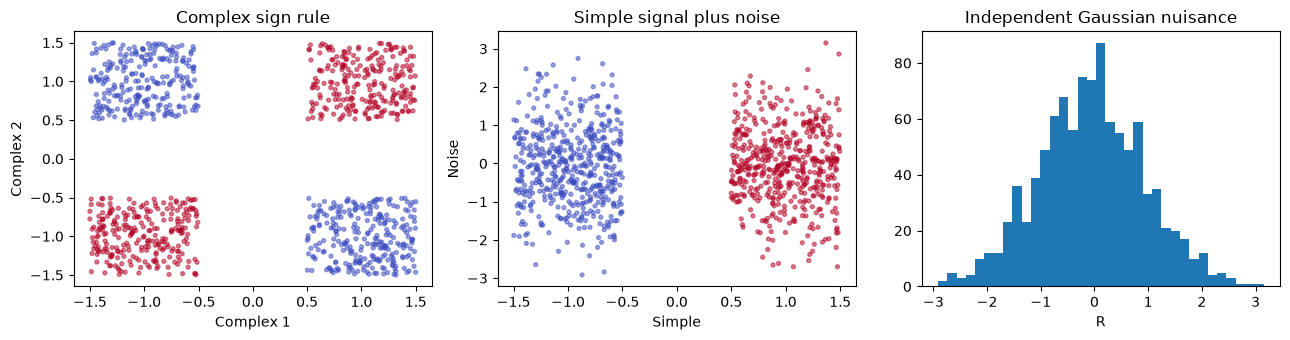

In [4]:
x, y = splits['train']
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].scatter(x[:,2], x[:,3], c=y[:,0], cmap='coolwarm', s=8, alpha=0.5)
axes[0].set(title='Complex sign rule', xlabel='Complex 1', ylabel='Complex 2')
axes[1].scatter(x[:,0], x[:,1], c=y[:,0], cmap='coolwarm', s=8, alpha=0.5)
axes[1].set(title='Simple signal plus noise', xlabel='Simple', ylabel='Noise')
axes[2].hist(x[:,1], bins=35)
axes[2].set(title='Independent Gaussian nuisance', xlabel='R')
fig.tight_layout(); plt.show()

## 3 Check initialization and gradients
Copy the three-input reference's shared columns, biases, and output layer.
The added column uses a separate seed, identically for C1 and C2, with
Uniform bounds $\pm1/\sqrt{3}$ matching the reference columns. Shared weights
are intentionally not redrawn using the default four-input fan-in bound.

Inverse initialization uses $W_c/\alpha$. Then the input contribution is
$(W_c/\alpha)(\alpha X_c)=W_cX_c$. At a matched state, backpropagation gives
$\nabla_{W_c^{(\alpha)}}L=\alpha g$. Effective weights are $V_c=\alpha W_c^{(\alpha)}$,
so ordinary SGD gives $\Delta V_c=-\eta\alpha^2g$. Dividing only the complex
gradients by $\alpha^2$ restores $\Delta V_c=-\eta g$.

In [9]:
rows = []
for dataset in DATASETS:
    for alpha in ALPHAS:
        reference = make_model(42, dataset)
        matched = make_model(42, dataset, alpha, 'inverse_init')
        errors = initial_checks(reference, matched, input_data(splits['train'],dataset),
                                input_data(splits['train'],dataset,alpha), dataset,alpha)
        assert max(errors.values()) < INITIAL_TOLERANCE
        rows.append(dict(dataset=dataset, alpha=alpha, **errors))
display(pd.DataFrame(rows))

,dataset,alpha,initial_preactivation_error,initial_logit_error,initial_gradient_scaling_error
0,C0_original,0.1,2.384186e-07,1.192093e-07,3.492460e-10
1,C0_original,0.5,0.000000e+00,0.000000e+00,0.000000e+00
2,C0_original,1.0,0.000000e+00,0.000000e+00,0.000000e+00
3,C0_original,2.0,0.000000e+00,0.000000e+00,0.000000e+00
4,C0_original,5.0,4.768372e-07,1.192093e-07,1.490116e-08
5,C0_original,10.0,4.768372e-07,1.192093e-07,2.980232e-08
6,C1_zero,0.1,2.384186e-07,1.192093e-07,3.492460e-10
7,C1_zero,0.5,0.000000e+00,0.000000e+00,0.000000e+00
8,C1_zero,1.0,0.000000e+00,0.000000e+00,0.000000e+00
9,C1_zero,2.0,0.000000e+00,0.000000e+00,0.000000e+00


## 4 Check the inactive coordinate and compensated trajectories
C1's nuisance weights have exactly zero gradient under plain SGD. C0 and C1
should therefore match up to floating point precision. We compare effective
shared parameters and logits, not a hard accuracy score alone.
The complete sweep repeats trajectory checks over all seeds and scales.

In [6]:
snapshots = {}
for dataset in DATASETS:
    data = {name: input_data(value,dataset) for name,value in splits.items()}
    model = make_model(42,dataset)
    if dataset == 'C1_zero':
        torch.nn.functional.binary_cross_entropy_with_logits(model(data['train'][0]),data['train'][1]).backward()
        assert torch.count_nonzero(model.fc1.weight.grad[:,1]) == 0
        model.zero_grad(set_to_none=True)
    _, snapshots[dataset] = train_model(model,data['train'],data['validation'],steps=25,
                                        dataset=dataset,conflicts=data['conflicts'])
    scaled = {name: input_data(value,dataset,5) for name,value in splits.items()}
    _, compensated = train_model(make_model(42,dataset,5,'compensated_sgd'),
        scaled['train'],scaled['validation'],steps=25,dataset=dataset,alpha=5,
        condition='compensated_sgd',conflicts=scaled['conflicts'])
    errors = compare_snapshots(compensated,snapshots[dataset])
    assert max(max(r['logit_error'],r['parameter_error']) for r in errors) < TRAJECTORY_TOLERANCE
    print(dataset, 'compensated maximum logit error:', max(r['logit_error'] for r in errors))
errors = compare_snapshots(snapshots['C1_zero'],snapshots['C0_original'],'shared_parameters')
assert max(max(r['logit_error'],r['parameter_error']) for r in errors) < TRAJECTORY_TOLERANCE
print('C0/C1 check passed:', errors)

C0_original compensated maximum logit error: 2.384185791015625e-07
C1_zero compensated maximum logit error: 2.384185791015625e-07
C2_noise compensated maximum logit error: 3.5762786865234375e-07
C0/C1 check passed: [{'step': 0, 'logit_error': 0.0, 'parameter_error': 0.0}, {'step': 25, 'logit_error': 0.0, 'parameter_error': 0.0}]


## 5 Save the unscaled data
These files include noise once. Each input condition is reconstructed from them.
Conflict labels name the complex implied rule; they are not ordinary test labels.

In [7]:
save_splits(ROOT / 'results' / 'data', splits)
print('Saved unscaled splits in results/data')

Saved unscaled splits in results/data
